# Task 03: Feature Engineering & Preprocessing Pipeline

**Objective:** Build a reusable, leak-free Scikit-Learn pipeline with missing-value imputation, categorical encoding, numerical scaling, correlation analysis, and feature-importance analysis.

**Dataset:** German Credit (`credit-g`) from OpenML. Internet access is required the first time the dataset is downloaded.

**Leakage prevention:** Split the raw data into training and test sets *before* fitting imputers, encoders, scalers, or feature-selection methods. All learned preprocessing is fitted only on the training data through the pipeline.

In [1]:
# 1. Import libraries
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [2]:
# 2. Load the German Credit dataset
# If this fails, check your internet connection and try running this cell again.
credit = fetch_openml("credit-g", version=1, as_frame=True)

X = credit.data.copy()
y = credit.target.copy()

print("Dataset shape:", X.shape)
print("\\nFirst five rows:")
display(X.head())
print("\\nTarget classes:")
print(y.value_counts(dropna=False))

Dataset shape: (1000, 20)
\nFirst five rows:


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


\nTarget classes:
class
good    700
bad     300
Name: count, dtype: int64


In [3]:
# 3. Basic dataset inspection
print("Data types:")
display(X.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

print("\\nMissing values per column (top 15):")
display(X.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

print("\\nDuplicate rows:", X.duplicated().sum())
print("\\nTarget distribution:")
display(y.value_counts(normalize=True).rename("proportion").to_frame())

Data types:


,column_count
dtype,
int64,7
category,1
category,1
category,1
category,1
category,1
category,1
category,1
category,1


\nMissing values per column (top 15):


,missing_count
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings_status,0
employment,0
installment_commitment,0
personal_status,0
other_parties,0


\nDuplicate rows: 0
\nTarget distribution:


,proportion
class,
good,0.7
bad,0.3


## 4. Train-test split before preprocessing

The test set is held out before any imputer, encoder, scaler, or feature-ranking method is fitted. The split is stratified so the target-class proportions are approximately preserved.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Training features: (800, 20)
Testing features: (200, 20)
Training target distribution:


,proportion
class,
good,0.7
bad,0.3


In [5]:
# 5. Identify numerical and categorical columns using the training data only
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical columns:", numeric_features)
print("\\nCategorical columns:", categorical_features)
print("\\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical columns: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
\nCategorical columns: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
\nNumber of numerical features: 7
Number of categorical features: 13


## 6. Build preprocessing pipelines

- **Numerical pipeline:** median imputation, then standard scaling.
- **Categorical pipeline:** most-frequent-value imputation, then one-hot encoding.
- `handle_unknown="ignore"` allows the pipeline to handle categories that appear in test/new data but were not present in training.

In [6]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['duration', 'credit_amount',
                                  'installment_commitment', 'residence_since',
                                  'age', 'existing_credits',
                                  'num_dependents']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['checking_status', 'credit_history',
                                  'purpose', 'savings_stat

## 7. Create and train the complete machine-learning pipeline

The preprocessing steps are inside the same pipeline as the model. Calling `fit` on training data learns imputation values, scaling parameters, and category mappings from the training set only.

In [7]:
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

model_pipeline.fit(X_train, y_train)
print("Pipeline training completed.")

Pipeline training completed.


Accuracy: 0.72
\nClassification report:
              precision    recall  f1-score   support

         bad       0.53      0.58      0.56        60
        good       0.81      0.78      0.80       140

    accuracy                           0.72       200
   macro avg       0.67      0.68      0.68       200
weighted avg       0.73      0.72      0.72       200

Confusion matrix:


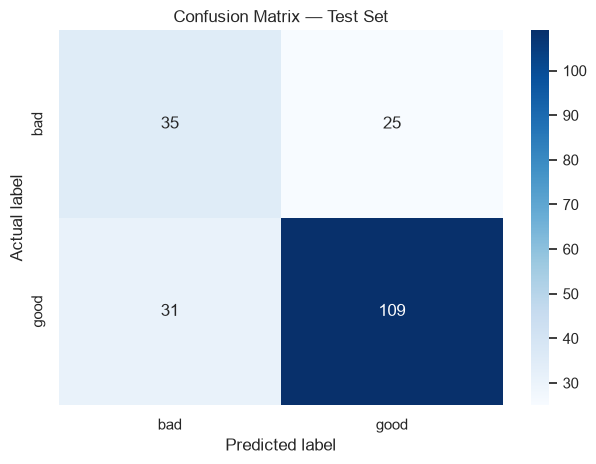

ROC-AUC: 0.7889


In [8]:
# 8. Evaluate on the held-out test set
y_pred = model_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
cm = confusion_matrix(y_test, y_pred, labels=model_pipeline.named_steps["classifier"].classes_)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=model_pipeline.named_steps["classifier"].classes_,
    yticklabels=model_pipeline.named_steps["classifier"].classes_
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

# ROC-AUC is calculated only for the binary case and when predict_proba is available.
classes = list(model_pipeline.named_steps["classifier"].classes_)
if len(classes) == 2:
    positive_class = classes[1]
    y_test_binary = (pd.Series(y_test, index=y_test.index) == positive_class).astype(int)
    positive_probs = model_pipeline.predict_proba(X_test)[:, classes.index(positive_class)]
    print("ROC-AUC:", round(roc_auc_score(y_test_binary, positive_probs), 4))

## 9. Correlation analysis

Pearson correlation is meaningful for numerical columns. The heatmap below is exploratory only; it is not used to fit the model or select features. Correlation does not imply causation.

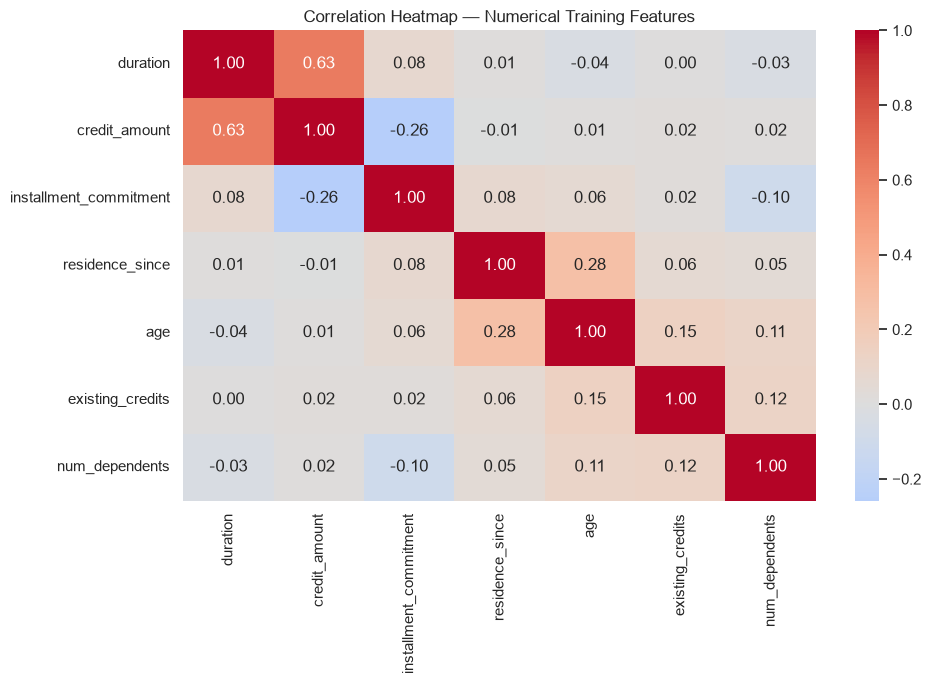

Numerical feature pairs with |correlation| >= 0.70:


,,correlation


In [9]:
if len(numeric_features) >= 2:
    corr = X_train[numeric_features].corr(numeric_only=True)
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=False)
    plt.title("Correlation Heatmap — Numerical Training Features")
    plt.tight_layout()
    plt.show()

    # Show strongly correlated pairs without repeating mirrored pairs
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    strong_pairs = (
        upper.stack()
        .rename("correlation")
        .loc[lambda s: s.abs() >= 0.70]
        .sort_values(key=lambda s: s.abs(), ascending=False)
    )
    print("Numerical feature pairs with |correlation| >= 0.70:")
    display(strong_pairs.to_frame())
else:
    print("Not enough numerical features for a correlation heatmap.")

## 10. Feature importance using Mutual Information

Mutual Information is calculated on the **training set only**. To keep this step leakage-safe, a separate preprocessing transformer is fitted on `X_train`, then the transformed training features are ranked against `y_train`. The test set is not used for feature ranking.

,feature,mutual_information
0,cat__checking_status_no checking,0.055525
1,cat__checking_status_<0,0.043478
2,cat__employment_<1,0.036016
3,cat__purpose_radio/tv,0.034352
4,cat__job_skilled,0.031170
5,cat__property_magnitude_no known property,0.028929
6,num__residence_since,0.023108
7,cat__credit_history_critical/other existing cr...,0.022914
8,cat__employment_4<=X<7,0.022240
9,cat__property_magnitude_real estate,0.019958


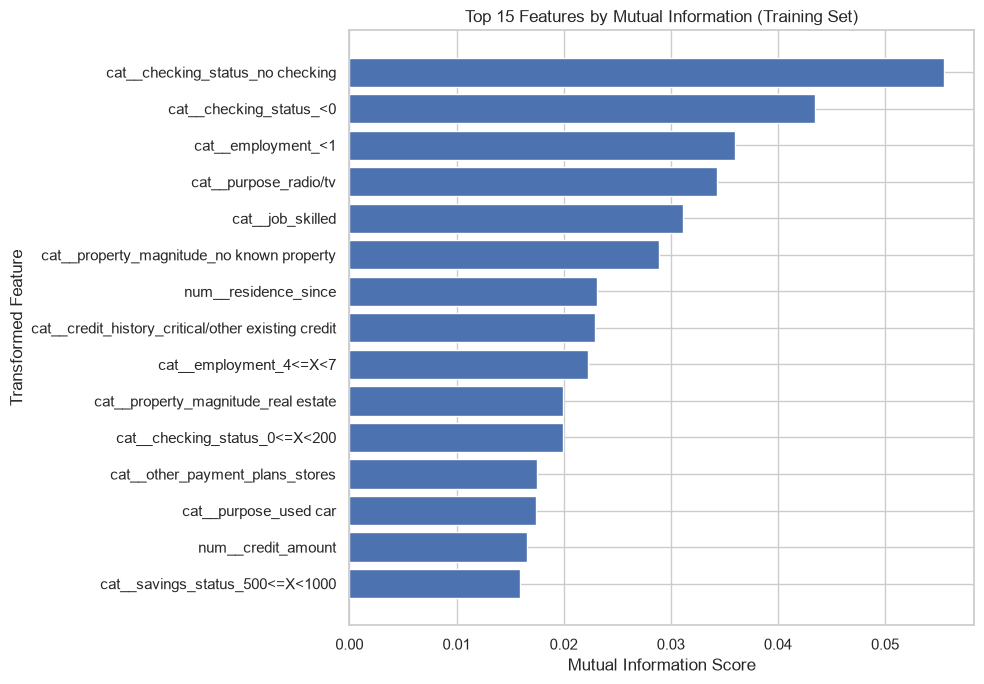

In [10]:
# Fit a separate copy of preprocessing on training data only for feature ranking
mi_preprocessor = preprocessor
X_train_transformed = mi_preprocessor.fit_transform(X_train)

# Retrieve readable feature names after one-hot encoding
feature_names = mi_preprocessor.get_feature_names_out()

# Convert sparse matrices when needed for mutual_info_classif
if hasattr(X_train_transformed, "toarray"):
    X_train_mi = X_train_transformed.toarray()
else:
    X_train_mi = np.asarray(X_train_transformed)

mi_scores = mutual_info_classif(
    X_train_mi,
    y_train,
    random_state=RANDOM_STATE
)

mi_ranking = (
    pd.DataFrame({"feature": feature_names, "mutual_information": mi_scores})
    .sort_values("mutual_information", ascending=False)
    .reset_index(drop=True)
)

display(mi_ranking.head(20))

plt.figure(figsize=(10, 7))
top_mi = mi_ranking.head(15).sort_values("mutual_information")
plt.barh(top_mi["feature"], top_mi["mutual_information"])
plt.xlabel("Mutual Information Score")
plt.ylabel("Transformed Feature")
plt.title("Top 15 Features by Mutual Information (Training Set)")
plt.tight_layout()
plt.show()

## 11. Tree-based feature importance

This uses the Random Forest already trained within the pipeline. The values indicate the model's impurity-based importance and should be interpreted as model-specific rankings, not causal effects.

,feature,importance
0,num__credit_amount,0.089491
1,num__age,0.078793
2,num__duration,0.077469
3,cat__checking_status_no checking,0.067089
4,cat__checking_status_<0,0.038990
5,num__residence_since,0.032976
6,num__installment_commitment,0.032967
7,cat__credit_history_critical/other existing cr...,0.024322
8,cat__savings_status_<100,0.022378
9,cat__checking_status_0<=X<200,0.018265


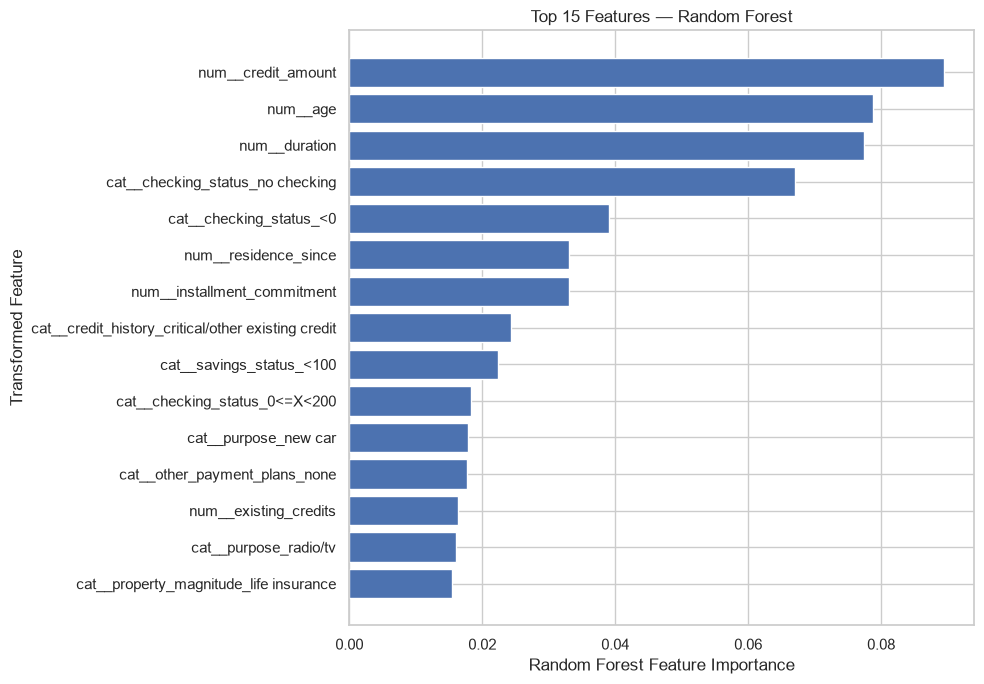

In [11]:
fitted_preprocessor = model_pipeline.named_steps["preprocessor"]
fitted_model = model_pipeline.named_steps["classifier"]
tree_feature_names = fitted_preprocessor.get_feature_names_out()

tree_importance = (
    pd.DataFrame({
        "feature": tree_feature_names,
        "importance": fitted_model.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(tree_importance.head(20))

plt.figure(figsize=(10, 7))
top_tree = tree_importance.head(15).sort_values("importance")
plt.barh(top_tree["feature"], top_tree["importance"])
plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Transformed Feature")
plt.title("Top 15 Features — Random Forest")
plt.tight_layout()
plt.show()

## 12. Reuse the trained pipeline for new records

Pass a DataFrame with the same raw column names used during training. The pipeline automatically applies the fitted imputation, encoding, scaling, and model prediction steps.

In [12]:
# Example: predict for a few rows from the held-out test set
sample_records = X_test.head(3)
sample_predictions = model_pipeline.predict(sample_records)

preview = sample_records.copy()
preview["predicted_class"] = sample_predictions
display(preview)

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,predicted_class
977,0<=X<200,18,delayed previously,business,2427,no known savings,>=7,4,male single,none,2,life insurance,42,none,own,2,skilled,1,none,yes,good
735,0<=X<200,36,all paid,domestic appliance,3990,no known savings,<1,3,female div/dep/mar,none,2,no known property,29,bank,own,1,unemp/unskilled non res,1,none,yes,bad
615,0<=X<200,48,no credits/all paid,business,12204,no known savings,1<=X<4,2,male single,none,2,car,48,bank,own,1,high qualif/self emp/mgmt,1,yes,yes,good


## 13. Final observations

Complete these points after running all cells and reviewing your actual outputs:

1. The dataset contains both numerical and categorical predictors.
2. Missing values are handled within pipelines using median and most-frequent imputation.
3. Numerical variables are standardized and categorical variables are one-hot encoded.
4. The raw data is split before fitting preprocessing steps, reducing the risk of data leakage.
5. Test-set metrics provide an estimate of generalization performance; they may vary with the split and dataset version.
6. Correlation and feature-importance scores describe associations or model behavior, not causation.
7. The complete `model_pipeline` can be reused to preprocess new records consistently.

**Important:** Do not write invented accuracy or feature-importance results in your report. Run the notebook and report the values generated in your own environment.